# MACHINE LEARNING IN DATA SCIENCE — LAB 02
## Building and Training Neural Networks with Scikit-Learn & PyTorch
**Tools:** Python 3.x, Scikit-learn, PyTorch, TorchVision

| Student Name | Student Roll Number |
|---|---|
| Bùi Minh Hoàng | SE193392 |

## Environment Setup
Install the libraries below in a Python environment, then select it as the notebook kernel.
For Part 3, use a CUDA version of PyTorch or a Google Colab GPU runtime.

```bash
pip install numpy pandas matplotlib seaborn scikit-learn torch torchvision ipykernel threadpoolctl
```
Run the notebook from top to bottom. CIFAR-10 is downloaded into `data/` on the first run.

In [1]:
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)
from joblib import parallel_backend
from threadpoolctl import threadpool_limits

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
threadpool_limits(limits=1)  # Avoid CPU thread oversubscription during grid search.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch: 2.15.0+cpu
CUDA available: False
Device: CPU


# PART 1 — Regression MLP (30 pts)
## 1.1 Data Preparation

In [2]:
housing = fetch_california_housing(data_home='data/sklearn')
X_train, X_test, y_train, y_test = train_test_split(
    housing.data, housing.target, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Training:', X_train_scaled.shape, y_train.shape)
print('Test:', X_test_scaled.shape, y_test.shape)
print('Features:', housing.feature_names)

Training: (16512, 8) (16512,)
Test: (4128, 8) (4128,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## 1.2 Baseline MLP Regressor

Test RMSE: 0.5428; R²: 0.7752
Iterations: 220


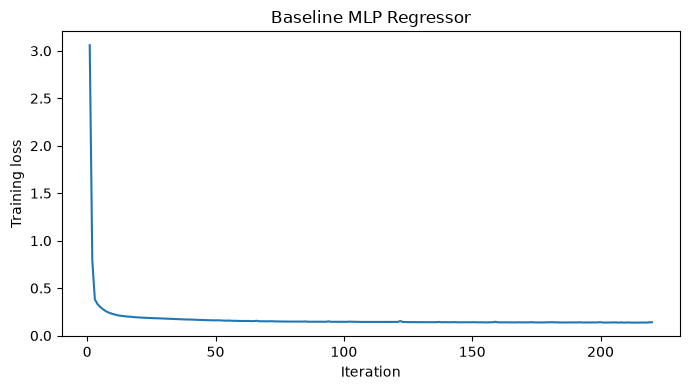

In [3]:
baseline_reg = MLPRegressor(hidden_layer_sizes=(64,), activation='relu',
                            solver='adam', max_iter=500, random_state=42)
baseline_reg.fit(X_train_scaled, y_train)
pred = baseline_reg.predict(X_test_scaled)
baseline_rmse = np.sqrt(mean_squared_error(y_test, pred))
baseline_r2 = r2_score(y_test, pred)
print(f'Test RMSE: {baseline_rmse:.4f}; R²: {baseline_r2:.4f}')
print('Iterations:', baseline_reg.n_iter_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, baseline_reg.n_iter_ + 1), baseline_reg.loss_curve_)
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.title('Baseline MLP Regressor')
plt.tight_layout()
plt.show()

**Convergence:** The training loss falls quickly and then flattens, with training stopping after 220 iterations.
This suggests that the model has reached a region where further training makes little progress under the default tolerance.
The test RMSE is 0.5428 and R² is 0.7752, so the model explains about 77.5% of the target variance on the test set.

## 1.3 Hyperparameter Tuning
The scaler is inside the pipeline so each CV fold fits its own scaler using only its training rows.
The full grid contains 24 combinations and uses 5-fold CV (120 fits).

In [4]:
reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(max_iter=500, random_state=42))
])
param_grid = {
    'mlp__hidden_layer_sizes': [(64,), (128, 64), (256, 128, 64)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__learning_rate_init': [0.01, 0.001],
    'mlp__alpha': [0.0001, 0.001],
}
grid = GridSearchCV(reg_pipeline, param_grid, cv=5,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
start = time.perf_counter()
with parallel_backend('loky', inner_max_num_threads=1):
    grid.fit(X_train, y_train)
print('Grid search time (seconds):', round(time.perf_counter() - start, 1))
print('Best parameters:', grid.best_params_)
print(f'Best CV RMSE: {-grid.best_score_:.4f}')
best_pred = grid.predict(X_test)
reg_results = pd.DataFrame({
    'Model': ['Baseline MLP', 'Tuned MLP'],
    'Test RMSE': [baseline_rmse, np.sqrt(mean_squared_error(y_test, best_pred))],
    'Test R²': [baseline_r2, r2_score(y_test, best_pred)]
})
display(reg_results.round(4))
cv_results = pd.DataFrame(grid.cv_results_)
display(cv_results.groupby(['param_mlp__hidden_layer_sizes', 'param_mlp__alpha'])[
    'mean_test_score'].max().mul(-1).rename('Best CV RMSE in group').round(4))

Grid search time (seconds): 411.1
Best parameters: {'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': 0.001}
Best CV RMSE: 0.5165


c:\Users\buimi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Test RMSE,Test R²
0,Baseline MLP,0.5428,0.7752
1,Tuned MLP,0.5078,0.8032


param_mlp__hidden_layer_sizes  param_mlp__alpha
(64,)                          0.0001              0.5491
                               0.0010              0.5482
(128, 64)                      0.0001              0.5165
                               0.0010              0.5196
(256, 128, 64)                 0.0001              0.5291
                               0.0010              0.5366
Name: Best CV RMSE in group, dtype: float64

**Comparison and interpretation:** Tuning improves test RMSE from **0.5428 to 0.5078** and R² from **0.7752 to 0.8032**.
Two hidden layers give the best CV RMSE (0.5165), compared with 0.5482 for one layer and 0.5291 for three layers, after selecting the best remaining settings within each depth.
More depth can learn more complex patterns, but the three-layer network does not improve this result and costs more to train.
L2 regularisation limits large weights, but the larger alpha of 0.001 does not consistently improve the best CV scores within each depth.
The selected model uses `(128, 64)`, `tanh`, `learning_rate_init=0.001` and `alpha=0.0001`.

**Training limit:** Some grid fits, including the final refit, reach 500 iterations and emit a convergence warning; a longer run could change the scores.

# PART 2 — Classification MLP (30 pts)
## 2.1 Data Exploration & Preparation

In [5]:
cancer = load_breast_cancer()
print('Class distribution:')
print(pd.Series(cancer.target).map(dict(enumerate(cancer.target_names))).value_counts())
print('Missing values:', np.isnan(cancer.data).sum())
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.2, stratify=cancer.target, random_state=42)
cancer_scaler = StandardScaler()
Xc_train_scaled = cancer_scaler.fit_transform(Xc_train)
Xc_test_scaled = cancer_scaler.transform(Xc_test)
print('Train / test:', Xc_train_scaled.shape, Xc_test_scaled.shape)

Class distribution:
benign       357
malignant    212
Name: count, dtype: int64
Missing values: 0
Train / test: (455, 30) (114, 30)


**Why scaling matters:** The features use different units and ranges.
Without scaling, large features can dominate weight updates and make gradient descent converge slowly or unevenly.
The scaler is fitted only on the training set to avoid leaking test information.

## 2.2 MLP Classifier
I use one hidden layer with 64 ReLU neurons, since this dataset is small and has only 30 input features.
This is enough to model non-linear relationships without making the network unnecessarily large.
Adam is a reasonable starting point because it adapts the learning rate for each parameter.

Training accuracy: 0.9978
Test accuracy: 0.9561
              precision    recall  f1-score   support

   malignant     0.9111    0.9762    0.9425        42
      benign     0.9855    0.9444    0.9645        72

    accuracy                         0.9561       114
   macro avg     0.9483    0.9603    0.9535       114
weighted avg     0.9581    0.9561    0.9564       114



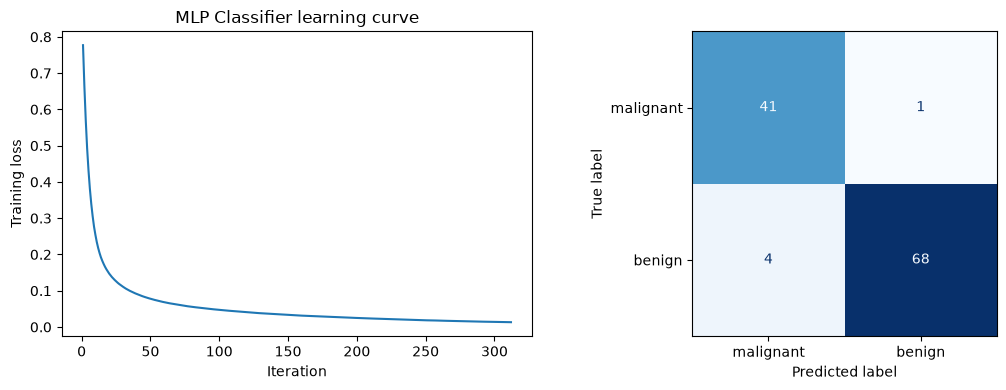

In [6]:
classifier = MLPClassifier(hidden_layer_sizes=(64,), activation='relu', solver='adam',
                           max_iter=500, early_stopping=False, random_state=42)
classifier.fit(Xc_train_scaled, yc_train)
yc_pred = classifier.predict(Xc_test_scaled)
print(f'Training accuracy: {classifier.score(Xc_train_scaled, yc_train):.4f}')
print(f'Test accuracy: {accuracy_score(yc_test, yc_pred):.4f}')
print(classification_report(yc_test, yc_pred, target_names=cancer.target_names, digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, classifier.n_iter_ + 1), classifier.loss_curve_)
axes[0].set(xlabel='Iteration', ylabel='Training loss', title='MLP Classifier learning curve')
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, display_labels=cancer.target_names,
                                       ax=axes[1], cmap='Blues', colorbar=False)
plt.tight_layout()
plt.show()

**Analysis:** Test accuracy is **95.61%**, compared with **99.78%** on the training set, which suggests some overfitting but still good performance on this split.
For malignant cases, precision is **0.9111** and recall is **0.9762**: the model misses 1 malignant case and incorrectly labels 4 benign cases as malignant.
This favours finding malignant cases at the cost of additional false alarms.
Adjusting the decision threshold would change this trade-off, and the small test set of 114 samples limits how confidently the result can be generalised.

## 2.3 Optimiser Comparison
Scikit-learn does not expose `loss_curve_` for L-BFGS.
The small subclass below records its objective evaluations, including line-search evaluations.
These are not epochs, so the horizontal axis has a different meaning for L-BFGS.

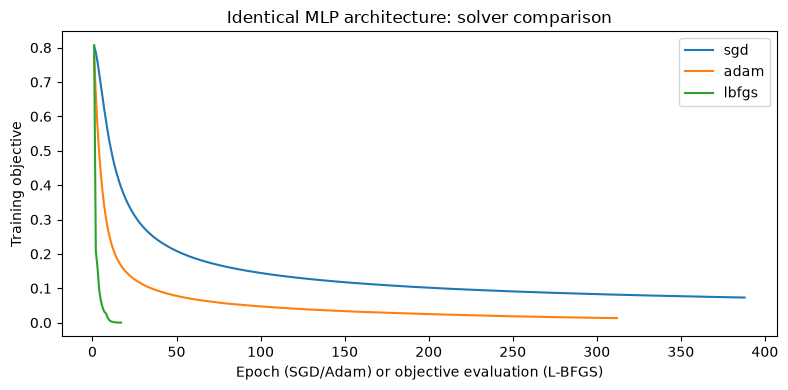

,Solver,Seconds,Iterations,Final loss,Test accuracy
0,sgd,0.4078,388,0.0730,0.9649
1,adam,0.3546,312,0.0132,0.9561
2,lbfgs,0.0289,16,0.0001,0.9561


In [7]:
class TracedMLPClassifier(MLPClassifier):
    def _loss_grad_lbfgs(self, *args, **kwargs):
        loss, gradient = super()._loss_grad_lbfgs(*args, **kwargs)
        if not hasattr(self, 'lbfgs_losses_'):
            self.lbfgs_losses_ = []
        self.lbfgs_losses_.append(float(loss))
        return loss, gradient

solver_results = []
plt.figure(figsize=(8, 4))
for solver in ['sgd', 'adam', 'lbfgs']:
    model = TracedMLPClassifier(hidden_layer_sizes=(64,), activation='relu', solver=solver,
                                max_iter=500, random_state=42)
    start = time.perf_counter()
    model.fit(Xc_train_scaled, yc_train)
    elapsed = time.perf_counter() - start
    losses = model.lbfgs_losses_ if solver == 'lbfgs' else model.loss_curve_
    plt.plot(range(1, len(losses) + 1), losses, label=solver)
    solver_results.append({'Solver': solver, 'Seconds': elapsed, 'Iterations': model.n_iter_,
                           'Final loss': model.loss_,
                           'Test accuracy': model.score(Xc_test_scaled, yc_test)})
plt.xlabel('Epoch (SGD/Adam) or objective evaluation (L-BFGS)')
plt.ylabel('Training objective')
plt.title('Identical MLP architecture: solver comparison')
plt.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(solver_results).round(4))

**Trade-offs:** L-BFGS is fastest in this run (0.0184 s) and reaches the lowest training objective (about 0.0001), which suits this small dataset.
Adam finishes in 312 iterations with loss 0.0132, while SGD needs 388 iterations and has loss 0.0730.
SGD nevertheless has the highest test accuracy (**96.49%**, versus **95.61%** for Adam and L-BFGS), showing that a lower training loss does not always mean better generalisation.
SGD usually needs more learning-rate tuning, Adam adapts its updates, and L-BFGS uses more memory on larger datasets; its plotted objective evaluations include line-search trials rather than epochs.

## 2.4 Early Stopping

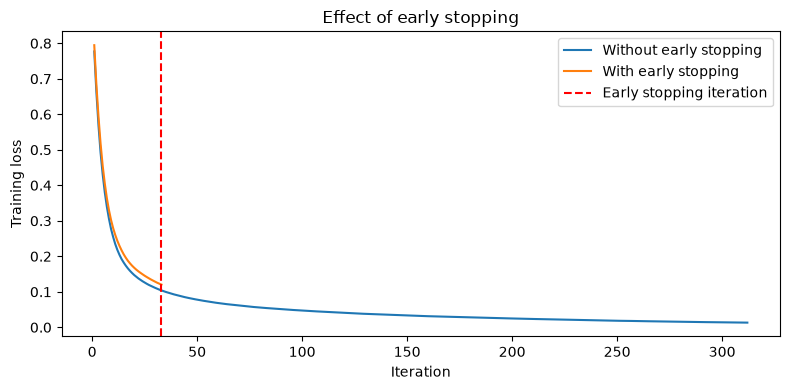

,Model,Iterations,Test accuracy
0,Without early stopping,312,0.9561
1,With early stopping,33,0.9649


Iterations saved: 279


In [8]:
# Reuse the exact baseline from 2.2 (early_stopping=False, max_iter=500).
early_classifier = MLPClassifier(
    hidden_layer_sizes=(64,), activation='relu', solver='adam', max_iter=500,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42)
early_classifier.fit(Xc_train_scaled, yc_train)
plt.figure(figsize=(8, 4))
plt.plot(range(1, classifier.n_iter_ + 1), classifier.loss_curve_, label='Without early stopping')
plt.plot(range(1, early_classifier.n_iter_ + 1), early_classifier.loss_curve_, label='With early stopping')
plt.axvline(early_classifier.n_iter_, color='red', linestyle='--', label='Early stopping iteration')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.title('Effect of early stopping')
plt.legend()
plt.tight_layout()
plt.show()
early_results = pd.DataFrame({
    'Model': ['Without early stopping', 'With early stopping'],
    'Iterations': [classifier.n_iter_, early_classifier.n_iter_],
    'Test accuracy': [classifier.score(Xc_test_scaled, yc_test),
                      early_classifier.score(Xc_test_scaled, yc_test)]
})
display(early_results.round(4))
print('Iterations saved:', classifier.n_iter_ - early_classifier.n_iter_)

**Discussion:** Early stopping improves test accuracy slightly, from **95.61% to 96.49%**, on this split.
It stops after **33 iterations**, compared with **312** without early stopping, saving **279 iterations**.
It monitors validation accuracy and restores the best validation weights, so training loss does not need to reach its minimum.
The trade-off is less data for fitting and sensitivity to the small validation set; this single split does not establish that early stopping will always improve accuracy.

# PART 3 — Deep Learning with PyTorch (40 pts)
## 3.1 PyTorch Fundamentals Review

In [9]:
image = torch.rand(3, 224, 224)
image = (image - image.mean()) / image.std()
print('Shape:', image.shape, 'dtype:', image.dtype)
print(f'Mean: {image.mean().item():.6f}; std: {image.std().item():.6f}')

a, b = torch.randn(2048, 2048), torch.randn(2048, 2048)
_ = a @ b  # Warm up before timing; report the mean of five multiplications.
start = time.perf_counter()
for _ in range(5):
    result_cpu = a @ b
cpu_time = (time.perf_counter() - start) / 5
print(f'CPU matrix multiplication: {cpu_time:.6f} seconds')
if device.type == 'cuda':
    ag, bg = a.to(device), b.to(device)
    _ = ag @ bg
    torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        result_gpu = ag @ bg
    torch.cuda.synchronize()
    gpu_time = (time.perf_counter() - start) / 5
    print(f'GPU: {gpu_time:.6f} seconds; speed-up: {cpu_time / gpu_time:.2f}x')
    print('GPU timing excludes CPU/GPU data transfers.')
else:
    print('GPU unavailable: GPU timing and speed-up cannot be measured.')

x = torch.tensor(2.0, requires_grad=True)
f = (x**2 + 3*x - 2)**3
f.backward()
analytical = 3 * (2**2 + 3*2 - 2)**2 * (2*2 + 3)
print('Autograd derivative:', x.grad.item(), '; analytical derivative:', analytical)
assert x.grad.item() == analytical == 1344

Shape: torch.Size([3, 224, 224]) dtype: torch.float32
Mean: 0.000000; std: 1.000000
CPU matrix multiplication: 0.049739 seconds
GPU unavailable: GPU timing and speed-up cannot be measured.
Autograd derivative: 1344.0 ; analytical derivative: 1344


By the chain rule, $f'(x)=3(x^2+3x-2)^2(2x+3)$.
At $x=2$, this gives $3(8)^2(7)=1344$, matching autograd.

## 3.2 CNN for CIFAR-10 Image Classification
### 3.2.1 Data Loading & Augmentation
I split the original 50,000 training images into 45,000 training and 5,000 validation images.
Validation and test images use normalisation only; the 10,000 test images are kept for final evaluation.

100.0%


Train / validation / test: 45000 5000 10000


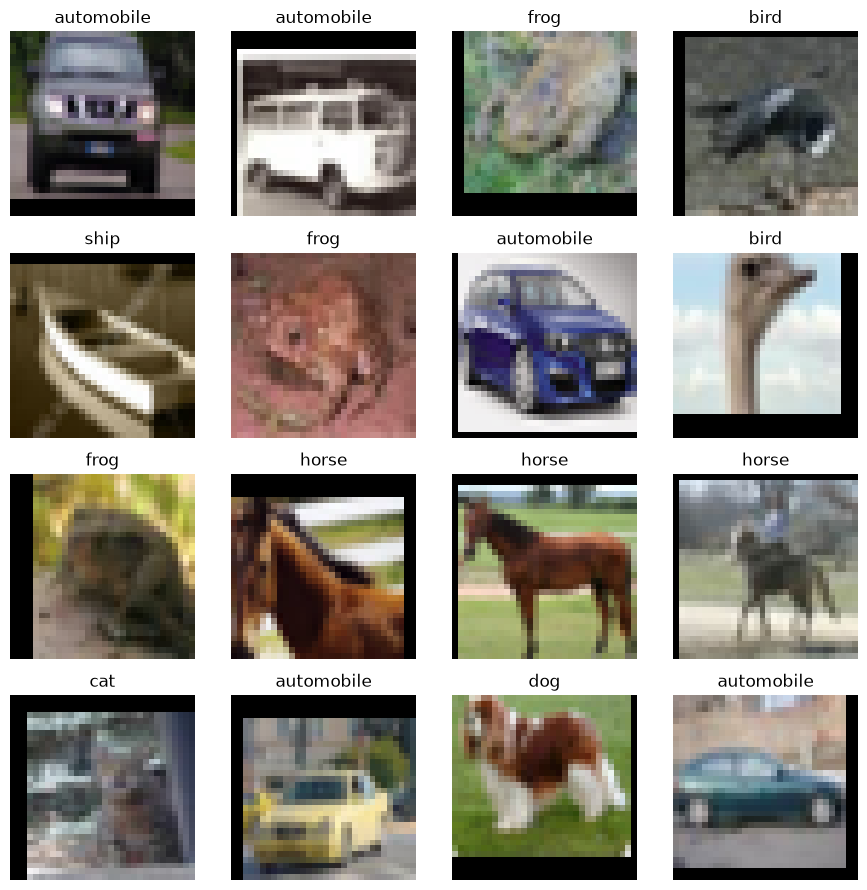

In [10]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(), transforms.Normalize(mean, std)
])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
train_data = datasets.CIFAR10('data', train=True, download=True, transform=train_transform)
val_data = datasets.CIFAR10('data', train=True, download=False, transform=eval_transform)
test_data = datasets.CIFAR10('data', train=False, download=True, transform=eval_transform)
train_idx, val_idx = train_test_split(np.arange(len(train_data)), test_size=0.1,
                                     stratify=train_data.targets, random_state=42)
train_loader = DataLoader(Subset(train_data, train_idx), batch_size=64, shuffle=True,
                          num_workers=2, pin_memory=device.type == 'cuda', persistent_workers=True)
val_loader = DataLoader(Subset(val_data, val_idx), batch_size=64, shuffle=False,
                        num_workers=2, pin_memory=device.type == 'cuda', persistent_workers=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False, num_workers=2,
                         pin_memory=device.type == 'cuda', persistent_workers=True)
print('Train / validation / test:', len(train_idx), len(val_idx), len(test_data))
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for ax, idx in zip(axes.flat, train_idx[:16]):
    img, label = train_data[int(idx)]
    img = img.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(train_data.classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3.2.2 Custom CNN Architecture

In [11]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, 256),
                                        nn.ReLU(), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

cnn = CustomCNN().to(device)
print(cnn)
print('Trainable parameters:', count_parameters(cnn))
with torch.no_grad():
    dummy_output = cnn(torch.randn(4, 3, 32, 32, device=device))
print('Forward output:', dummy_output.shape)
assert dummy_output.shape == (4, 10)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, ke

### 3.2.3 Training Loop

Epoch 01/30: train loss=1.5285, val loss=1.3949, train acc=0.4264, val acc=0.5002
Epoch 02/30: train loss=1.1831, val loss=1.0832, train acc=0.5711, val acc=0.6138
Epoch 03/30: train loss=1.0567, val loss=1.0286, train acc=0.6211, val acc=0.6324
Epoch 04/30: train loss=0.9740, val loss=0.9119, train acc=0.6499, val acc=0.6728
Epoch 05/30: train loss=0.9113, val loss=0.9008, train acc=0.6737, val acc=0.6852
Epoch 06/30: train loss=0.8605, val loss=0.8303, train acc=0.6951, val acc=0.7066
Epoch 07/30: train loss=0.8211, val loss=0.8380, train acc=0.7097, val acc=0.7178
Epoch 08/30: train loss=0.7786, val loss=0.7319, train acc=0.7239, val acc=0.7426
Epoch 09/30: train loss=0.7417, val loss=0.7056, train acc=0.7402, val acc=0.7564
Epoch 10/30: train loss=0.7104, val loss=0.6312, train acc=0.7514, val acc=0.7822
Epoch 11/30: train loss=0.6267, val loss=0.5606, train acc=0.7841, val acc=0.8044
Epoch 12/30: train loss=0.6013, val loss=0.5474, train acc=0.7908, val acc=0.8144
Epoch 13/30: tra

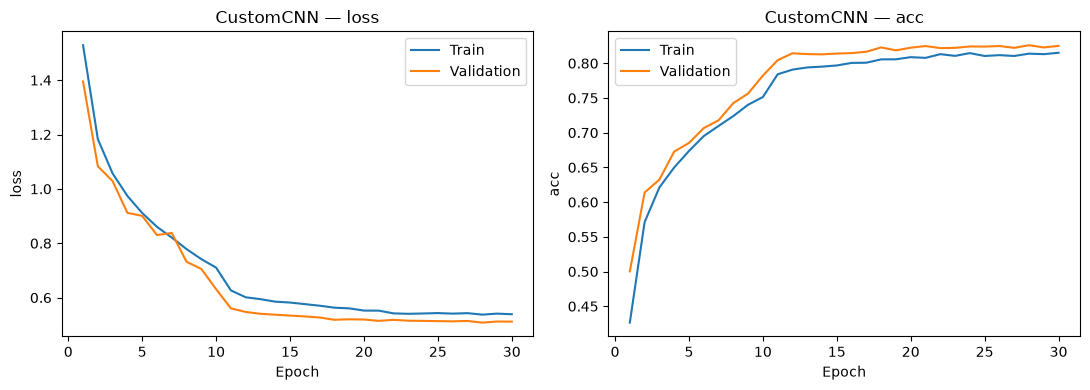

In [12]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def train_model(model, optimizer, scheduler, epochs=30):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    start = time.perf_counter()
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        scheduler.step()
        print(f'Epoch {epoch+1:02d}/{epochs}: train loss={train_loss:.4f}, '
              f'val loss={val_loss:.4f}, train acc={train_acc:.4f}, val acc={val_acc:.4f}', flush=True)
    return history, time.perf_counter() - start

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = range(1, len(history['train_loss']) + 1)
    for ax, metric in zip(axes, ['loss', 'acc']):
        ax.plot(epochs, history['train_' + metric], label='Train')
        ax.plot(epochs, history['val_' + metric], label='Validation')
        ax.set(xlabel='Epoch', ylabel=metric, title=title + ' — ' + metric)
        ax.legend()
    plt.tight_layout()
    plt.show()

optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
cnn_history, cnn_seconds = train_model(cnn, optimizer, scheduler, epochs=30)
cnn_test_loss, cnn_test_acc = run_epoch(cnn, test_loader)
print(f'CustomCNN test accuracy: {cnn_test_acc:.4f}; training time: {cnn_seconds:.1f}s')
plot_history(cnn_history, 'CustomCNN')

**Overfitting and regularisation:** CustomCNN reaches **82.19% test accuracy**, with final training accuracy **81.48%** and validation accuracy **82.98%**.
The training and validation losses both level off, with no clear late increase in validation loss, so the curves do not show strong overfitting.
Validation accuracy is slightly higher because training uses random augmentation and dropout, while validation uses clean images in evaluation mode.
Random crop, horizontal flip and dropout already regularise this network; weight decay or validation-based early stopping could help if overfitting appears in a longer run.

## 3.3 Residual Connections
### 3.3.1 Residual Block Implementation
The projection shortcut matches the number of channels and spatial size when these change.
The bottleneck reduces the internal channels to one quarter of its output channels.

In [13]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels)
        )
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels))
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.main(x) + self.shortcut(x))

class BottleneckBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        width = out_channels // 4
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, width, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU(),
            nn.Conv2d(width, width, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(width), nn.ReLU(),
            nn.Conv2d(width, out_channels, 1, bias=False), nn.BatchNorm2d(out_channels)
        )
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels))
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.main(x) + self.shortcut(x))

for block_class in [ResidualBlock, BottleneckBlock]:
    for out_channels, stride in [(16, 1), (32, 2)]:
        block = block_class(16, out_channels, stride)
        x = torch.randn(4, 16, 32, 32, requires_grad=True)
        output = block(x)
        output.square().mean().backward()
        print(f'\n{block_class.__name__}, channels={out_channels}, stride={stride}, output={tuple(output.shape)}')
        print('Input gradient norm:', x.grad.norm().item())
        for name, parameter in block.named_parameters():
            if name.endswith('weight'):
                print(name, 'gradient norm:', parameter.grad.norm().item())
        assert output.shape == (4, out_channels, 32 // stride, 32 // stride)
        assert torch.isfinite(x.grad).all() and x.grad.norm() > 0

# Isolate the identity shortcut: zero the residual branch so only the skip path remains.
block = ResidualBlock(16, 16)
for parameter in block.main.parameters():
    nn.init.zeros_(parameter)
x = torch.ones(1, 16, 4, 4, requires_grad=True)
block(x).sum().backward()
print('Skip-only gradient norm:', x.grad.norm().item())
assert torch.allclose(x.grad, torch.ones_like(x))


ResidualBlock, channels=16, stride=1, output=(4, 16, 32, 32)
Input gradient norm: 0.009852745570242405
main.0.weight gradient norm: 0.3744293749332428
main.1.weight gradient norm: 0.024144073948264122
main.3.weight gradient norm: 0.38433942198753357
main.4.weight gradient norm: 0.24796192348003387

ResidualBlock, channels=32, stride=2, output=(4, 32, 16, 16)
Input gradient norm: 0.01132083497941494
main.0.weight gradient norm: 0.20082888007164001
main.1.weight gradient norm: 0.00748694222420454
main.3.weight gradient norm: 0.25465214252471924
main.4.weight gradient norm: 0.17872409522533417
shortcut.0.weight gradient norm: 0.05772079527378082
shortcut.1.weight gradient norm: 0.17831212282180786

BottleneckBlock, channels=16, stride=1, output=(4, 16, 32, 32)
Input gradient norm: 0.010553495027124882
main.0.weight gradient norm: 0.10516908019781113
main.1.weight gradient norm: 0.019559884443879128
main.3.weight gradient norm: 0.16277915239334106
main.4.weight gradient norm: 0.0210396908

Non-zero gradients in the main branch and projection shortcut show that both paths participate in backpropagation.
In the final check, the residual branch is zero and the input is positive, so the gradient through the identity shortcut is exactly one at each element.
This direct path helps gradients reach earlier layers in a deep network.

### 3.3.2 Mini ResNet on CIFAR-10
ResNet-20 uses one initial convolution, nine residual blocks with two convolutions each, and a final linear layer: 1 + 9 × 2 + 1 = 20 layers.
Projection shortcuts add parameters when the channel count changes.

ResNet-20 trainable parameters: 272474
Epoch 01/30: train loss=1.7437, val loss=1.6307, train acc=0.3470, val acc=0.4176
Epoch 02/30: train loss=1.3313, val loss=1.4445, train acc=0.5143, val acc=0.5188
Epoch 03/30: train loss=1.0321, val loss=1.0597, train acc=0.6347, val acc=0.6570
Epoch 04/30: train loss=0.8416, val loss=0.9181, train acc=0.7055, val acc=0.6910
Epoch 05/30: train loss=0.7334, val loss=0.8317, train acc=0.7464, val acc=0.7216
Epoch 06/30: train loss=0.6644, val loss=0.7081, train acc=0.7701, val acc=0.7646
Epoch 07/30: train loss=0.6120, val loss=0.7552, train acc=0.7880, val acc=0.7386
Epoch 08/30: train loss=0.5761, val loss=0.7174, train acc=0.7997, val acc=0.7668
Epoch 09/30: train loss=0.5408, val loss=0.6188, train acc=0.8124, val acc=0.7924
Epoch 10/30: train loss=0.5091, val loss=0.6321, train acc=0.8229, val acc=0.7908
Epoch 11/30: train loss=0.4824, val loss=0.4943, train acc=0.8330, val acc=0.8280
Epoch 12/30: train loss=0.4586, val loss=0.5724, train acc=

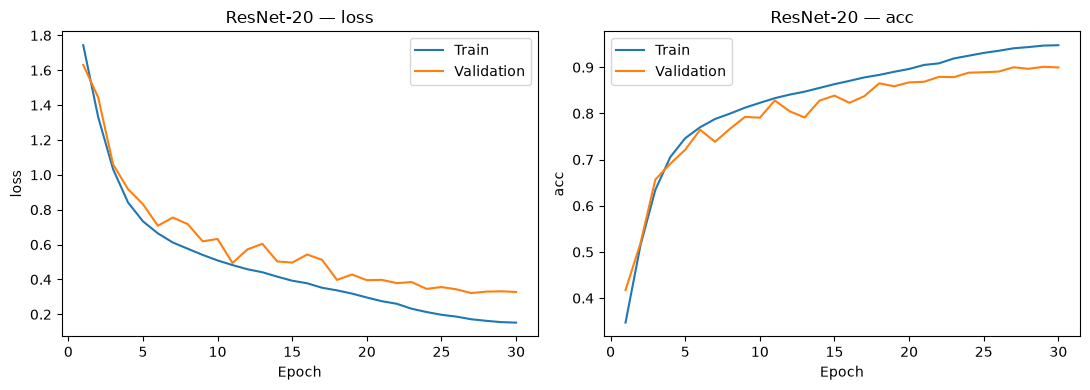

,Model,Parameters,Test accuracy,Training seconds
0,CustomCNN,175658,0.8199,1844.3416
1,ResNet-20,272474,0.8953,2430.2769


In [14]:
class ResNet20(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU()
        self.group1 = nn.Sequential(*[ResidualBlock(16, 16) for _ in range(3)])
        self.group2 = nn.Sequential(ResidualBlock(16, 32, stride=2),
                                    ResidualBlock(32, 32), ResidualBlock(32, 32))
        self.group3 = nn.Sequential(ResidualBlock(32, 64, stride=2),
                                    ResidualBlock(64, 64), ResidualBlock(64, 64))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.group3(self.group2(self.group1(x)))
        return self.fc(self.pool(x).flatten(1))

torch.manual_seed(42)
resnet = ResNet20().to(device)
print('ResNet-20 trainable parameters:', count_parameters(resnet))
with torch.no_grad():
    assert resnet(torch.randn(4, 3, 32, 32, device=device)).shape == (4, 10)
optimizer = torch.optim.SGD(resnet.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
resnet_history, resnet_seconds = train_model(resnet, optimizer, scheduler, epochs=30)
resnet_test_loss, resnet_test_acc = run_epoch(resnet, test_loader)
plot_history(resnet_history, 'ResNet-20')
comparison = pd.DataFrame({
    'Model': ['CustomCNN', 'ResNet-20'],
    'Parameters': [count_parameters(cnn), count_parameters(resnet)],
    'Test accuracy': [cnn_test_acc, resnet_test_acc],
    'Training seconds': [cnn_seconds, resnet_seconds]
})
display(comparison.round(4))

**Comparison:** ResNet-20 achieves **89.31% test accuracy**, compared with **82.19%** for CustomCNN, an improvement of **7.12 percentage points**.
It uses **272,474 parameters** versus **175,658**, and takes about **354.0 s** to train versus **234.7 s** on this machine.
Both networks use the same split, augmentation, batch size and 30-epoch budget, but use the different optimisers and schedulers required by the lab, so this does not isolate architecture alone.
Skip connections give gradients a direct path through the deeper network.
ResNet's final training accuracy is **94.83%** versus **88.74%** validation accuracy, showing some overfitting despite its stronger test result.

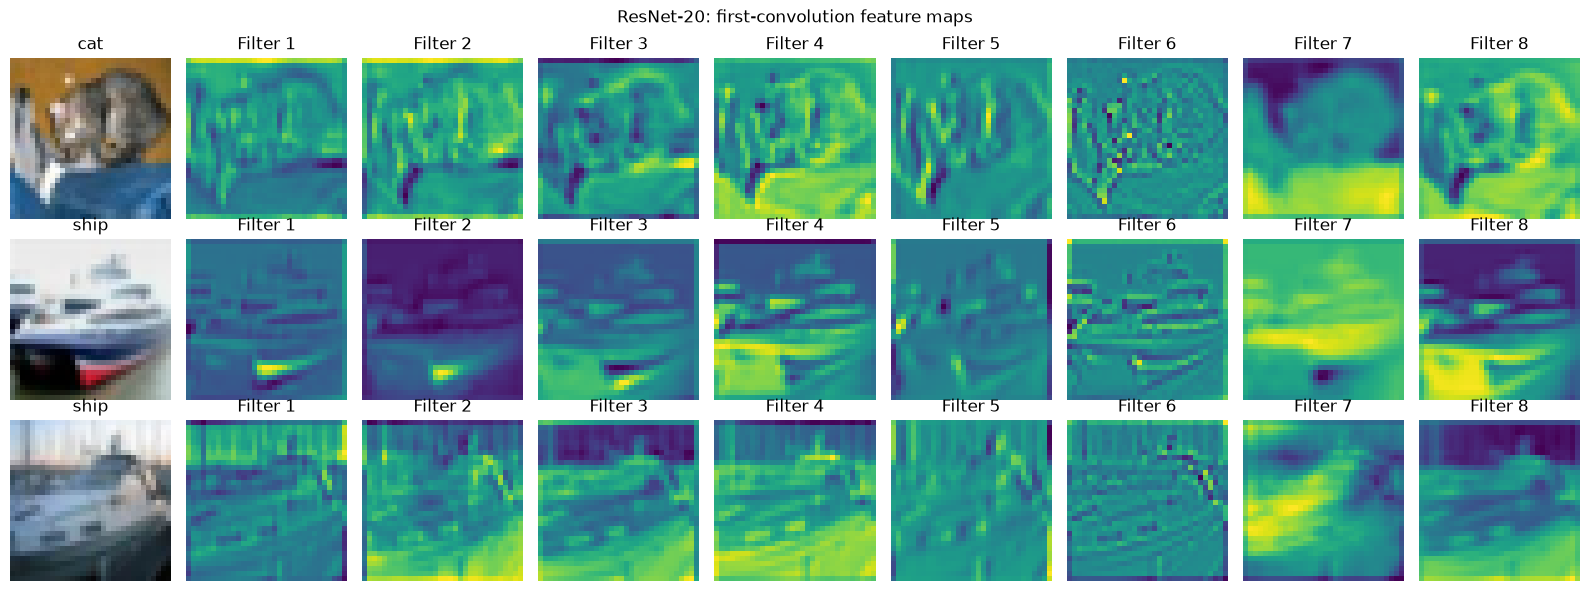

In [15]:
# Show the first eight feature maps from the first convolution for three test images.
resnet.eval()
fig, axes = plt.subplots(3, 9, figsize=(16, 6))
with torch.no_grad():
    for row in range(3):
        image, label = test_data[row]
        maps = resnet.conv1(image.unsqueeze(0).to(device))[0].cpu()
        original = image.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)
        axes[row, 0].imshow(np.clip(original, 0, 1))
        axes[row, 0].set_title(test_data.classes[label])
        for channel in range(8):
            axes[row, channel + 1].imshow(maps[channel], cmap='viridis')
            axes[row, channel + 1].set_title(f'Filter {channel+1}')
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('ResNet-20: first-convolution feature maps')
plt.tight_layout()
plt.show()

**Feature maps:** The first convolution responds to local patterns such as edges, colours and textures.
Different filters activate at different locations of the same image.
These early maps are simple features, which later layers combine into more useful representations for classification.